# LAG 2v2 ACMI データ確認

`acmi` は選択したファイルの **pandas.DataFrame** です。1行は「ある時刻のオブジェクト更新」、列は位置・姿勢・プロパティです。`acmi.shape`、`type(acmi)`、`acmi.dtypes`、`acmi.describe()` を直接実行できます。

原本は `../raw/20261005_LAG_2v2_ACMI/`。ACMI 3本、対応動画3本、説明メモをコピーしています。ファイルを変更するには下の `ACMI_FILE` を変更して以降を再実行してください。

このローダーは今回の6成分 `T` レコードに対応します。省略された値は欠損のまま保持し、補間・前方補完はしません。削除行は `removals`、ヘッダーとグローバル属性は `metadata` に分けます。全オブジェクトが毎時刻存在するテンソルではありません。

末尾の「Action データ確認」では、同じ試合のCSVを `actions` に読み込み、離散行動・確率・発射記録を確認できます。

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Notebookのディレクトリ、実験ルート、リポジトリルートのいずれからでも実行可。
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
EXPERIMENT_DIR = next(
    p for base in candidates
    for p in (base, base / "13_LAG", base / "experiments" / "13_LAG",
              base / "mental-modeling-openai" / "experiments" / "13_LAG")
    if (p / "data" / "viz" / "acmi_loader.py").is_file()
)
DATA_DIR = EXPERIMENT_DIR / "data" / "raw" / "20261005_LAG_2v2_ACMI"
sys.path.insert(0, str(EXPERIMENT_DIR / "data" / "viz"))
from acmi_loader import load_acmi, TRANSFORM_COLUMNS
pd.set_option("display.max_columns", 30)
files = sorted(DATA_DIR.glob("*.acmi"))
assert files, f"ACMI files not found: {DATA_DIR}"
display(pd.DataFrame({"file": [p.name for p in files], "bytes": [p.stat().st_size for p in files]}))

,file,bytes
0,mhi_v1.3_ic100601_win.acmi,297226
1,ours_seed100100_ic100601_loss.acmi,253931
2,ours_seed100100_ic100606_win.acmi,400633


In [2]:
ACMI_FILE = "mhi_v1.3_ic100601_win.acmi"
# ACMI_FILE = "ours_seed100100_ic100601_loss.acmi"
# ACMI_FILE = "ours_seed100100_ic100606_win.acmi"
acmi_path = DATA_DIR / ACMI_FILE
acmi_text = acmi_path.read_text(encoding="utf-8-sig")
acmi, removals, metadata = load_acmi(acmi_path)
print("raw text type:", type(acmi_text), "characters:", len(acmi_text))
print("acmi type:", type(acmi))
print("acmi.shape (rows, columns):", acmi.shape)
display(metadata)
display(acmi.head(10))

raw text type: <class 'str'> characters: 297223
acmi type: <class 'pandas.DataFrame'>
acmi.shape (rows, columns): (1907, 16)


{'FileType': 'text/acmi/tacview',
 'FileVersion': '2.1',
 'ReferenceTime': '2020-04-01T00:00:00Z'}

,time_s,object_id,line_number,longitude_deg,latitude_deg,altitude_m,roll_deg,pitch_deg,yaw_deg,Name,Color,TAS,Health,Missiles,Type,Radius
0,0.0,A0100,5,120.003456,60.007197,6096.000000,-2.255996e-15,1.769903e-15,356.970401,F16,Red,243.8,100.0,2.0,<NA>,NaN
1,0.0,A0200,6,119.990039,60.004227,6096.000000,-1.684500e-15,-2.500951e-15,10.802050,F16,Red,243.8,100.0,2.0,<NA>,NaN
2,0.0,B0100,7,120.017262,60.178810,6096.000000,1.099981e-15,2.927492e-15,170.552671,F16,Blue,243.8,100.0,2.0,<NA>,NaN
3,0.0,B0200,8,119.993470,60.173442,6096.000000,5.487662e-15,-7.057424e-15,191.604675,F16,Blue,243.8,100.0,2.0,<NA>,NaN
4,0.2,A0100,10,120.003409,60.007633,6095.924894,-8.872458e-01,-1.127140e+00,357.019091,F16,Red,242.9,100.0,2.0,<NA>,NaN
5,0.2,A0200,11,119.990202,60.004656,6095.968273,-4.600987e+00,-1.136465e+00,10.500656,F16,Red,242.7,100.0,2.0,<NA>,NaN
6,0.2,B0100,12,120.017406,60.178379,6095.877117,2.249095e+00,7.022711e-01,170.745079,F16,Blue,243.3,100.0,2.0,<NA>,NaN
7,0.2,B0200,13,119.993294,60.173015,6096.027924,-3.026409e+00,6.282438e-01,191.373107,F16,Blue,242.8,100.0,2.0,<NA>,NaN
8,0.4,A0100,15,120.003363,60.008067,6095.389477,2.457629e+00,-4.240173e+00,357.424146,F16,Red,242.4,100.0,2.0,<NA>,NaN
9,0.4,A0200,16,119.990364,60.005082,6095.818365,-9.853794e+00,-4.213552e+00,10.954630,F16,Red,241.6,100.0,2.0,<NA>,NaN


## 型・欠損・統計量

位置は経度・緯度（度）、高度（m）、姿勢はroll・pitch・yaw（度）として展開しています。`TAS`、`Health`、`Missiles`、`Radius`は原文の属性名を保持します。値の定義は同梱メモや生成側実装で確認してください。角度の平均・標準偏差は通常の算術統計であり、循環角としての統計ではありません。

機体・ミサイル・その他の表示オブジェクトが混在するため、全体の統計と機体のみの統計を分けて確認します。

In [3]:
acmi.info()
schema = pd.DataFrame({
    "dtype": acmi.dtypes.astype(str),
    "non_null": acmi.notna().sum(),
    "missing": acmi.isna().sum(),
    "missing_pct": acmi.isna().mean().mul(100).round(2),
    "unique": acmi.nunique(),
})
display(schema)
display(acmi.drop(columns="line_number").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 1907 entries, 0 to 1906
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   time_s         1907 non-null   float64
 1   object_id      1907 non-null   string 
 2   line_number    1907 non-null   int64  
 3   longitude_deg  1907 non-null   float64
 4   latitude_deg   1907 non-null   float64
 5   altitude_m     1907 non-null   float64
 6   roll_deg       1907 non-null   float64
 7   pitch_deg      1907 non-null   float64
 8   yaw_deg        1907 non-null   float64
 9   Name           1901 non-null   string 
 10  Color          1907 non-null   string 
 11  TAS            1155 non-null   float64
 12  Health         1155 non-null   float64
 13  Missiles       1155 non-null   float64
 14  Type           8 non-null      string 
 15  Radius         8 non-null      float64
dtypes: float64(11), int64(1), string(4)
memory usage: 263.5 KB


,dtype,non_null,missing,missing_pct,unique
time_s,float64,1907,0,0.00,342
object_id,string,1907,0,0.00,18
line_number,int64,1907,0,0.00,1907
longitude_deg,float64,1907,0,0.00,1901
latitude_deg,float64,1907,0,0.00,1901
altitude_m,float64,1907,0,0.00,1900
roll_deg,float64,1907,0,0.00,1158
pitch_deg,float64,1907,0,0.00,1901
yaw_deg,float64,1907,0,0.00,1901
Name,string,1901,6,0.31,3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time_s,1907.0,NaN,NaN,NaN,31.958364,18.39699,0.0,16.8,29.4,46.3,68.2
object_id,1907,18,A0100,342,NaN,NaN,NaN,NaN,NaN,NaN,NaN
longitude_deg,1907.0,NaN,NaN,NaN,120.068775,0.074241,119.990039,120.001809,120.040774,120.127529,120.228136
latitude_deg,1907.0,NaN,NaN,NaN,60.080468,0.037276,60.004227,60.056033,60.074891,60.096844,60.17881
altitude_m,1907.0,NaN,NaN,NaN,4975.999124,662.017879,3670.131653,4578.100775,5068.061962,5369.754844,6143.448429
roll_deg,1907.0,NaN,NaN,NaN,-9.642147,34.661745,-116.064698,-15.793287,0.0,0.0,99.977155
pitch_deg,1907.0,NaN,NaN,NaN,-4.612445,5.633549,-26.787817,-7.764112,-4.958291,-0.734521,36.6064
yaw_deg,1907.0,NaN,NaN,NaN,146.04234,101.61633,0.037708,83.525675,118.283019,179.957234,371.288191
Name,1901,3,F16,1155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Color,1907,2,Blue,1022,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
times = pd.Series(sorted(acmi.time_s.unique()), name="time_s")
print("time range [s]:", times.min(), "→", times.max())
print("distinct timestamps:", len(times), "objects:", acmi.object_id.nunique())
print("duplicate (time, object) update rows:", acmi.duplicated(["time_s", "object_id"]).sum())
display(times.diff().dropna().describe().rename("timestamp interval [s]"))
object_summary = acmi.groupby("object_id").agg(
    name=("Name", "first"), color=("Color", "first"),
    rows=("time_s", "size"), first_update_s=("time_s", "min"), last_update_s=("time_s", "max"),
)
display(object_summary)
display(removals)

time range [s]: 0.0 → 68.2
distinct timestamps: 342 objects: 18
duplicate (time, object) update rows: 0


count    3.410000e+02
mean     2.000000e-01
std      2.863509e-15
min      2.000000e-01
25%      2.000000e-01
50%      2.000000e-01
75%      2.000000e-01
max      2.000000e-01
Name: timestamp interval [s], dtype: float64

,name,color,rows,first_update_s,last_update_s
object_id,,,,,
A0100,F16,Red,342,0.0,68.2
A01001,AIM-9L,Red,23,62.4,66.8
A01001F,<NA>,Red,1,67.0,67.0
A01002,AIM-9L,Red,89,9.4,27.0
A01002F,<NA>,Red,1,27.2,27.2
A0200,F16,Red,342,0.0,68.2
A02002,AIM-9L,Red,86,10.0,27.0
A02002F,<NA>,Red,1,27.2,27.2
B0100,F16,Blue,335,0.0,66.8


,time_s,object_id,line_number
0,27.2,B0200,1036
1,27.2,A01002,1038
2,27.2,A02002,1041
3,47.6,B02002,1715
4,48.6,B01002,1747
5,67.0,B0100,2231
6,67.0,A01001,2234
7,68.2,B01001,2259


In [5]:
aircraft = acmi.loc[acmi["Name"].eq("F16")].copy()
print("aircraft.shape:", aircraft.shape)
features = TRANSFORM_COLUMNS + ["TAS", "Health", "Missiles"]
display(aircraft[features].describe().T)
display(aircraft.groupby(["object_id", "Color"])[["altitude_m", "TAS", "Health", "Missiles"]].agg(["count", "mean", "std", "min", "max"]))

aircraft.shape: (1155, 16)


,count,mean,std,min,25%,50%,75%,max
longitude_deg,1155.0,120.072298,0.079353,119.990039,120.002601,120.035637,120.141187,120.228136
latitude_deg,1155.0,60.077323,0.042937,60.004227,60.048592,60.063564,60.102902,60.178810
altitude_m,1155.0,5019.979785,726.535670,3670.131653,4453.683178,5275.351105,5517.862346,6143.448429
roll_deg,1155.0,-15.822221,43.380756,-116.064698,-44.984801,-6.014303,0.525045,99.977155
pitch_deg,1155.0,-5.072089,6.058598,-21.666485,-8.756013,-5.913232,-1.263467,35.424931
yaw_deg,1155.0,125.655709,90.119870,0.037708,70.184725,100.132886,178.314791,359.980389
TAS,1155.0,303.531948,30.344872,231.600000,286.100000,310.200000,328.900000,347.100000
Health,1155.0,100.000000,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000
Missiles,1155.0,1.006926,0.576808,0.000000,1.000000,1.000000,1.000000,2.000000


altitude_m                                                     \
                     count         mean         std          min          max   
object_id Color                                                                 
A0100     Red          342  5322.535183  312.295808  4628.261542  6096.000000   
A0200     Red          342  4687.637396  791.158734  3670.131653  6096.000000   
B0100     Blue         335  4800.077185  790.864192  3734.141936  6143.305414   
B0200     Blue         136  5636.557150  350.177958  5051.622961  6143.448429   

                  TAS                                      Health              \
                count        mean        std    min    max  count   mean  std   
object_id Color                                                                 
A0100     Red     342  301.311111  25.383978  240.6  336.3    342  100.0  0.0   
A0200     Red     342  314.921930  30.879760  236.4  347.1    342  100.0  0.0   
B0100     Blue    335  304.291343  28.274729  231.6  334.9    335  100.0  0.0   
B0200     Blue    136  278.603676  29.807952  234.1  317.0    136  100.0  0.0   

                              Missiles                                
                   min    max    count      mean       std  min  max  
object_id Color                                                       
A0100     Red    100.0  100.0      342  1.049708  0.472576  0.0  2.0  
A0200     Red    100.0  100.0      342  1.146199  0.353823  1.0  2.0  
B0100     Blue   100.0  100.0      335  0.683582  0.726858  0.0  2.0  
B0200     Blue   100.0  100.0      136  1.345588  0.477318  1.0  2.0

## 機体別の推移と座標

経緯度の軌跡は座標の概観用で、距離を正確に表す地図投影ではありません。線は記録点を結んだものです。

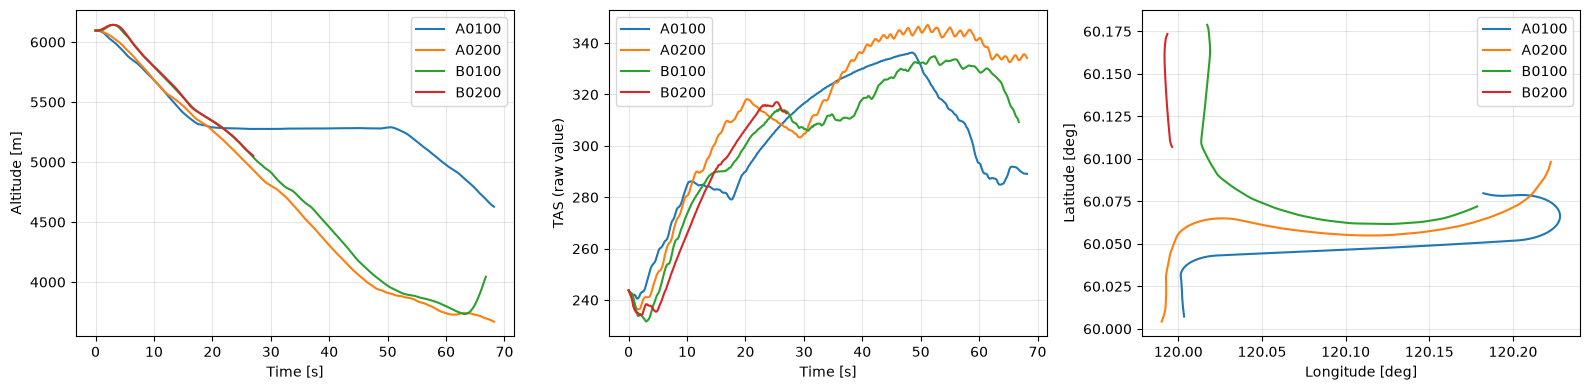

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for object_id, group in aircraft.groupby("object_id"):
    group = group.sort_values("time_s")
    axes[0].plot(group.time_s, group.altitude_m, label=object_id)
    axes[1].plot(group.time_s, group.TAS, label=object_id)
    axes[2].plot(group.longitude_deg, group.latitude_deg, label=object_id)
for ax, xlabel, ylabel in zip(axes, ["Time [s]", "Time [s]", "Longitude [deg]"], ["Altitude [m]", "TAS (raw value)", "Latitude [deg]"]):
    ax.set(xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

## 3ファイルの比較と自由な操作

`acmi_by_file` に全ファイルのDataFrameを保持します。`acmi`は上で選択した1本のままです。

In [7]:
acmi_by_file = {p.name: load_acmi(p)[0] for p in files}
display(pd.DataFrame([
    {"file": name, "rows": len(df), "columns": df.shape[1],
     "timestamps": df.time_s.nunique(), "objects": df.object_id.nunique(),
     "start_s": df.time_s.min(), "end_s": df.time_s.max()}
    for name, df in acmi_by_file.items()
]))

,file,rows,columns,timestamps,objects,start_s,end_s
0,mhi_v1.3_ic100601_win.acmi,1907,16,342,18,0.0,68.2
1,ours_seed100100_ic100601_loss.acmi,1646,16,295,17,0.0,58.8
2,ours_seed100100_ic100606_win.acmi,2575,16,497,18,0.0,99.2


## Action データ確認

[actions/README.md](../raw/20261005_LAG_2v2_ACMI/actions/README.md) に基づく行動の確認です。上の `ACMI_FILE` と同じ試合を読みます。

- `actions`: CSV全体。1行は時刻tの1機の状態と、その状態から選んだ行動。行動はt〜t+0.2秒に効きます。
- `policy_actions`: 生存中の学習モデル側（赤）の行だけ。
- `action`: 4種類の離散行動だけを取り出したDataFrame。
- `action_probabilities`: 各選択肢の確率13列。

青（固定ルール）と撃墜後の行動・確率の空欄は仕様上の欠損です。ゼロや`no`では埋めません。CSVの状態列は、モデルに渡された観測ベクトルそのものではありません。RNN内部状態も含みません。

| 行動 | 選択肢 | 意味 |
|---|---|---|
| altitude_action | up / hold / down | 高度目標の変化 |
| heading_action | left30 / left15 / hold / right15 / right30 | 方位目標の変化（度） |
| speed_action | up / hold / down | 速度目標の変化（約±17 m/s） |
| shoot_action | no / yes | 発射意思。実際の発射はmissile_launchedを参照 |

In [8]:
import numpy as np

ACTIONS_DIR = DATA_DIR / "actions"
ACTION_FILE = f"{Path(ACMI_FILE).stem}_actions.csv"
ACTION_OPTIONS = {
    "altitude": ["up", "hold", "down"],
    "heading": ["left30", "left15", "hold", "right15", "right30"],
    "speed": ["up", "hold", "down"],
    "shoot": ["no", "yes"],
}
ACTION_COLUMNS = [f"{branch}_action" for branch in ACTION_OPTIONS]
PROBABILITY_COLUMNS = [f"p_{branch}_{option}" for branch, options in ACTION_OPTIONS.items() for option in options]
text_columns = ["uid", "color", "controller", "missile_launched", *ACTION_COLUMNS]

def read_actions(path):
    return pd.read_csv(path, dtype={column: "string" for column in text_columns})

actions = read_actions(ACTIONS_DIR / ACTION_FILE)
policy_actions = actions.loc[actions.controller.eq("learned") & actions.alive.eq(1)].copy()
action = policy_actions[ACTION_COLUMNS].copy()
action_probabilities = policy_actions[PROBABILITY_COLUMNS].copy()
print("file:", ACTION_FILE)
for name, value in [("actions", actions), ("policy_actions", policy_actions), ("action", action), ("action_probabilities", action_probabilities)]:
    print(name, "type:", type(value), "shape:", value.shape)
with pd.option_context("display.max_columns", None):
    display(actions.head(8))

file: mhi_v1.3_ic100601_win_actions.csv
actions type: <class 'pandas.DataFrame'> shape: (1364, 34)
policy_actions type: <class 'pandas.DataFrame'> shape: (682, 34)
action type: <class 'pandas.DataFrame'> shape: (682, 4)
action_probabilities type: <class 'pandas.DataFrame'> shape: (682, 13)


,step,time_s,uid,color,controller,alive,lon_deg,lat_deg,alt_m,roll_deg,pitch_deg,yaw_deg,tas_mps,vn_mps,ve_mps,vu_mps,altitude_action,p_altitude_up,p_altitude_hold,p_altitude_down,heading_action,p_heading_left30,p_heading_left15,p_heading_hold,p_heading_right15,p_heading_right30,speed_action,p_speed_up,p_speed_hold,p_speed_down,shoot_action,p_shoot_no,p_shoot_yes,missile_launched
0,0,0.0,A0100,Red,learned,1,120.003456,60.007197,6096.000000,-2.255996e-15,1.769903e-15,356.970401,243.840000,243.499201,-12.887391,-6.958782e-16,down,0.003947,0.060048,0.936005,right15,0.025997,0.046158,0.184034,0.696162,0.047649,up,0.993361,0.001441,0.005198,yes,0.002591,0.997409,<NA>
1,0,0.0,A0200,Red,learned,1,119.990039,60.004227,6096.000000,-1.684500e-15,-2.500951e-15,10.802050,243.840000,239.519288,45.699632,-5.164794e-14,down,0.027181,0.155999,0.816820,left15,0.148553,0.850411,0.000452,0.000340,0.000244,up,0.779040,0.155887,0.065073,no,0.956651,0.043349,<NA>
2,0,0.0,B0100,Blue,rule_pursue,1,120.017262,60.178810,6096.000000,1.099981e-15,2.927492e-15,170.552671,243.840000,-240.532776,40.024106,1.551856e-14,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>
3,0,0.0,B0200,Blue,rule_pursue,1,119.993470,60.173442,6096.000000,5.487662e-15,-7.057424e-15,191.604675,243.840000,-238.855628,-49.050328,1.014745e-14,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>
4,1,0.2,A0100,Red,learned,1,120.003409,60.007633,6095.924894,-8.872458e-01,-1.127140e+00,357.019091,242.934469,242.591699,-12.860739,-1.012474e+00,down,0.006146,0.123136,0.870718,right15,0.026244,0.051396,0.245048,0.628944,0.048367,up,0.995120,0.001425,0.003455,yes,0.002011,0.997989,<NA>
5,1,0.2,A0200,Red,learned,1,119.990202,60.004656,6095.968273,-4.600987e+00,-1.136465e+00,10.500656,242.723061,238.435883,45.417979,-1.441121e-01,down,0.022204,0.145755,0.832041,left15,0.113438,0.885296,0.000518,0.000459,0.000290,up,0.837113,0.111775,0.051112,no,0.965978,0.034022,<NA>
6,1,0.2,B0100,Blue,rule_pursue,1,120.017406,60.178379,6095.877117,2.249095e+00,7.022711e-01,170.745079,243.257098,-239.959734,39.898729,-1.197240e+00,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>
7,1,0.2,B0200,Blue,rule_pursue,1,119.993294,60.173015,6096.027924,-3.026409e+00,6.282438e-01,191.373107,242.798509,-237.848087,-48.774265,6.887564e-01,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>


### 型・欠損・統計量

全行の欠損と、生存中の学習モデル側の欠損を並べます。状態・確率の統計量も後者を対象にします。角度の平均は算術平均です。

In [9]:
actions.info()
display(pd.DataFrame({
    "dtype": actions.dtypes.astype(str),
    "missing_all": actions.isna().sum(),
    "missing_policy_alive": policy_actions.isna().sum(),
    "unique_all": actions.nunique(),
}))
display(actions.groupby(["uid", "color", "controller", "alive"]).size().rename("rows").to_frame())
display(policy_actions.select_dtypes(include="number").drop(columns=["step", "alive"]).describe().T)
display(action.describe().T)

<class 'pandas.DataFrame'>
RangeIndex: 1364 entries, 0 to 1363
Data columns (total 34 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   step               1364 non-null   int64  
 1   time_s             1364 non-null   float64
 2   uid                1364 non-null   string 
 3   color              1364 non-null   string 
 4   controller         1364 non-null   string 
 5   alive              1364 non-null   int64  
 6   lon_deg            1364 non-null   float64
 7   lat_deg            1364 non-null   float64
 8   alt_m              1364 non-null   float64
 9   roll_deg           1364 non-null   float64
 10  pitch_deg          1364 non-null   float64
 11  yaw_deg            1364 non-null   float64
 12  tas_mps            1364 non-null   float64
 13  vn_mps             1364 non-null   float64
 14  ve_mps             1364 non-null   float64
 15  vu_mps             1364 non-null   float64
 16  altitude_action    682 non-null    

,dtype,missing_all,missing_policy_alive,unique_all
step,int64,0,0,341
time_s,float64,0,0,341
uid,string,0,0,4
color,string,0,0,2
controller,string,0,0,2
alive,int64,0,0,2
lon_deg,float64,0,0,1155
lat_deg,float64,0,0,1155
alt_m,float64,0,0,1154
roll_deg,float64,0,0,1155


rows
uid   color controller  alive      
A0100 Red   learned     1       341
A0200 Red   learned     1       341
B0100 Blue  rule_pursue 0         6
                        1       335
B0200 Blue  rule_pursue 0       205
                        1       136

,count,mean,std,min,25%,50%,75%,max
time_s,682.0,34.000000,19.702009,0.000000,17.000000,34.000000,51.000000,68.000000
lon_deg,682.0,120.096487,0.085541,119.990039,120.003326,120.087051,120.185004,120.228136
lat_deg,682.0,60.050776,0.019450,60.004227,60.043156,60.051717,60.062405,60.097573
alt_m,682.0,5007.596230,678.710252,3674.070095,4633.108290,5276.019355,5352.308589,6096.000000
roll_deg,682.0,-15.069224,51.189686,-116.064698,-54.393238,-9.850782,1.595932,99.977155
pitch_deg,682.0,-4.425224,4.226398,-16.152643,-7.437388,-4.943601,-0.393259,6.301469
yaw_deg,682.0,107.072312,108.272766,0.037708,35.138045,83.608904,101.774694,359.980389
tas_mps,682.0,308.105588,29.070977,236.432031,288.234764,312.583573,333.374646,347.114915
vn_mps,682.0,136.108306,131.133893,-119.504951,28.431302,132.270730,261.997231,331.220252
ve_mps,682.0,168.347752,174.716289,-288.157940,28.027136,260.409402,316.816761,339.442190


,count,unique,top,freq
altitude_action,682,2,down,370
heading_action,682,5,left15,162
speed_action,682,3,up,488
shoot_action,682,2,yes,412


### 行動の頻度・確率の確認

頻度の分母は各機体・各行動の記録済み選択数です。確率の合計と、選択された行動が最大確率を持つことも確認します。

In [10]:
frequency_rows = []
probability_checks = []
for branch, options in ACTION_OPTIONS.items():
    column = f"{branch}_action"
    for uid, group in policy_actions.groupby("uid"):
        counts = group[column].value_counts().reindex(options, fill_value=0)
        for option, count in counts.items():
            frequency_rows.append({"uid": uid, "branch": branch, "option": option, "count": count,
                                   "fraction": count / group[column].notna().sum()})
    columns = [f"p_{branch}_{option}" for option in options]
    probabilities = policy_actions[columns]
    values = probabilities.to_numpy(dtype=float)
    selected = policy_actions[column].map({option: i for i, option in enumerate(options)})
    known = selected.notna().to_numpy()
    selected_prob = np.full(len(selected), np.nan)
    selected_prob[known] = values[np.flatnonzero(known), selected.loc[known].astype(int).to_numpy()]
    probability_checks.append({
        "branch": branch,
        "missing_probability_cells": int(probabilities.isna().sum().sum()),
        "out_of_range_cells": int(((probabilities < 0) | (probabilities > 1)).sum().sum()),
        "max_sum_error": float((probabilities.sum(axis=1, min_count=len(columns)) - 1).abs().max()),
        "unknown_or_missing_choices": int((~known).sum()),
        "non_max_choices": int((known & ~np.isclose(selected_prob, values.max(axis=1), atol=1e-7, rtol=0)).sum()),
    })
action_frequencies = pd.DataFrame(frequency_rows)
display(action_frequencies)
display(pd.DataFrame(probability_checks))
print("duplicate (step, uid):", actions.duplicated(["step", "uid"]).sum())
print("max |time_s - step * 0.2|:", (actions.time_s - actions.step * 0.2).abs().max())

,uid,branch,option,count,fraction
0,A0100,altitude,up,0,0.000000
1,A0100,altitude,hold,187,0.548387
2,A0100,altitude,down,154,0.451613
3,A0200,altitude,up,0,0.000000
4,A0200,altitude,hold,125,0.366569
5,A0200,altitude,down,216,0.633431
6,A0100,heading,left30,70,0.205279
7,A0100,heading,left15,29,0.085044
8,A0100,heading,hold,161,0.472141
9,A0100,heading,right15,45,0.131965


,branch,missing_probability_cells,out_of_range_cells,max_sum_error,unknown_or_missing_choices,non_max_choices
0,altitude,0,0,1.266599e-07,0,0
1,heading,0,0,1.839362e-07,0,0
2,speed,0,0,1.296867e-07,0,0
3,shoot,0,0,8.638017e-08,0,0


duplicate (step, uid): 0
max |time_s - step * 0.2|: 1.4210854715202004e-14


### 機体別の行動と確率の時系列

`ACTION_UID` を `A0100` / `A0200` に変更して再実行できます。左は選択された行動、右は各選択肢の確率です。

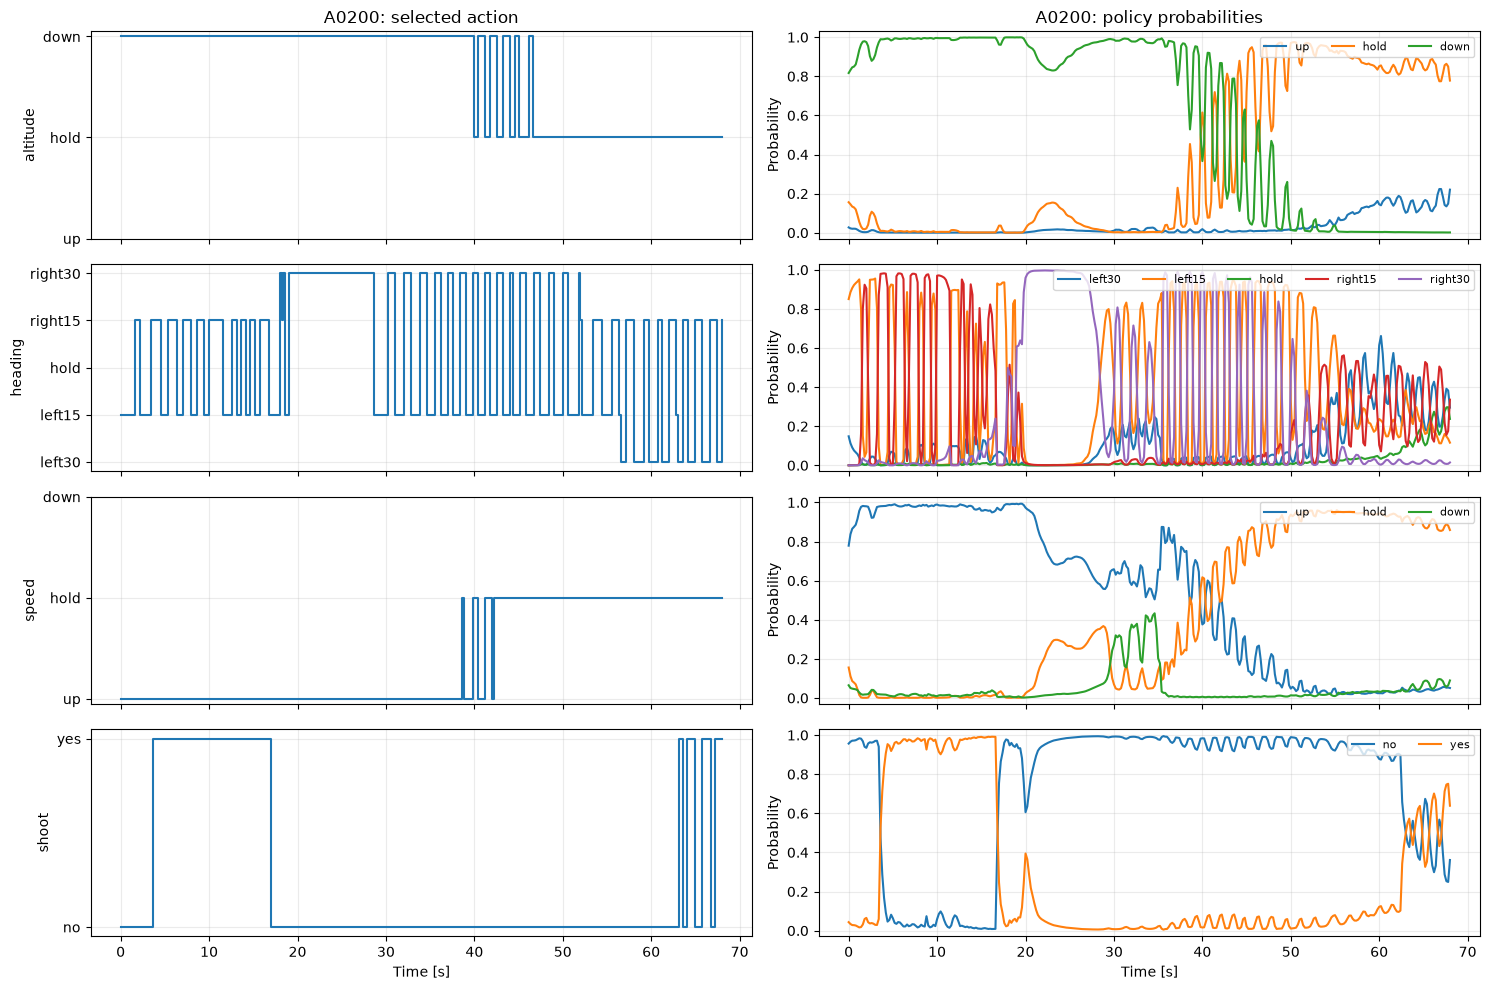

In [15]:
ACTION_UID = "A0200"
agent_actions = policy_actions.loc[policy_actions.uid.eq(ACTION_UID)].sort_values("time_s")
assert not agent_actions.empty, f"No learned/alive action rows: {ACTION_UID}"
fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex=True)
for row, (branch, options) in enumerate(ACTION_OPTIONS.items()):
    indices = agent_actions[f"{branch}_action"].map({option: i for i, option in enumerate(options)})
    axes[row, 0].step(agent_actions.time_s, indices, where="post")
    axes[row, 0].set(yticks=range(len(options)), yticklabels=options, ylabel=branch)
    for option in options:
        axes[row, 1].plot(agent_actions.time_s, agent_actions[f"p_{branch}_{option}"], label=option)
    axes[row, 1].set(ylim=(-0.03, 1.03), ylabel="Probability")
    axes[row, 1].legend(loc="upper right", fontsize=8, ncol=len(options))
for ax in axes.flat:
    ax.grid(alpha=0.25)
for ax in axes[-1]:
    ax.set_xlabel("Time [s]")
axes[0, 0].set_title(f"{ACTION_UID}: selected action")
axes[0, 1].set_title(f"{ACTION_UID}: policy probabilities")
fig.tight_layout()
plt.show()

### 発射意思と実際の発射

`shoot_action=yes` は発射回数ではありません。発射条件を満たして実際に発射されたミサイルIDは `missile_launched` に記録されます。下の表は意思のあったステップ数と、発射記録のある行数を分けて表示します。青側の発射もイベント一覧に含めます。

In [12]:
shoot_summary = policy_actions.assign(
    shoot_requested=policy_actions.shoot_action.eq("yes"),
    launch_recorded=policy_actions.missile_launched.notna(),
).groupby("uid").agg(
    policy_steps=("step", "size"),
    shoot_yes_steps=("shoot_requested", "sum"),
    launch_rows=("launch_recorded", "sum"),
)
display(shoot_summary)
launch_events = actions.loc[actions.missile_launched.notna(),
    ["step", "time_s", "uid", "controller", "shoot_action", "p_shoot_yes", "missile_launched"]]
display(launch_events)

,policy_steps,shoot_yes_steps,launch_rows
uid,,,
A0100,341,328,2
A0200,341,84,1


,step,time_s,uid,controller,shoot_action,p_shoot_yes,missile_launched
184,46,9.2,A0100,learned,yes,0.982665,A01002
187,46,9.2,B0200,rule_pursue,<NA>,NaN,B02002
197,49,9.8,A0200,learned,yes,0.976816,A02002
206,51,10.2,B0100,rule_pursue,<NA>,NaN,B01002
706,176,35.2,B0100,rule_pursue,<NA>,NaN,B01001
1244,311,62.2,A0100,learned,yes,0.944054,A01001


### ACMIの状態と同時刻で結合

`step × 0.2秒` と機体IDで結合し、`actions_with_acmi` に残します。CSVの最終行は最後の行動前、ACMIにはその行動後の状態もあるため終端が1ステップずれる場合があります。ACMIにない状態は欠損のままです。

In [13]:
acmi_states = aircraft[["time_s", "object_id", *TRANSFORM_COLUMNS]].copy()
acmi_states["step"] = np.rint(acmi_states.time_s / 0.2).astype(int)
assert np.allclose(acmi_states.time_s, acmi_states.step * 0.2, atol=1e-6, rtol=0)
acmi_states = acmi_states.rename(columns={"object_id": "uid", **{c: f"acmi_{c}" for c in TRANSFORM_COLUMNS}}).drop(columns="time_s")
actions_with_acmi = actions.merge(acmi_states, on=["step", "uid"], how="left", validate="one_to_one", indicator="acmi_match")
display(actions_with_acmi.groupby(["alive", "acmi_match"], observed=True).size().rename("rows").to_frame())
coordinate_pairs = {"lon_deg": "longitude_deg", "lat_deg": "latitude_deg", "alt_m": "altitude_m",
                    "roll_deg": "roll_deg", "pitch_deg": "pitch_deg", "yaw_deg": "yaw_deg"}
display(pd.DataFrame([
    {"csv_column": source, "matched_rows": actions_with_acmi[f"acmi_{target}"].notna().sum(),
     "max_absolute_difference": (actions_with_acmi[source] - actions_with_acmi[f"acmi_{target}"]).abs().max()}
    for source, target in coordinate_pairs.items()
]))
display(actions_with_acmi.loc[actions_with_acmi.uid.eq(ACTION_UID),
    ["step", "time_s", "uid", "alt_m", "acmi_altitude_m", *ACTION_COLUMNS]].head(10))

,,rows
alive,acmi_match,
0,left_only,211
1,both,1153


,csv_column,matched_rows,max_absolute_difference
0,lon_deg,1153,1.421085e-14
1,lat_deg,1153,7.105427e-15
2,alt_m,1153,4.547474e-13
3,roll_deg,1153,2.842171e-14
4,pitch_deg,1153,7.105427e-15
5,yaw_deg,1153,5.684342e-14


,step,time_s,uid,alt_m,acmi_altitude_m,altitude_action,heading_action,speed_action,shoot_action
0,0,0.0,A0100,6096.000000,6096.000000,down,right15,up,yes
4,1,0.2,A0100,6095.924894,6095.924894,down,right15,up,yes
8,2,0.4,A0100,6095.389477,6095.389477,down,right15,up,yes
12,3,0.6,A0100,6093.668947,6093.668947,down,hold,up,yes
16,4,0.8,A0100,6090.553777,6090.553777,down,left15,up,yes
20,5,1.0,A0100,6086.369093,6086.369093,down,left15,up,yes
24,6,1.2,A0100,6081.241273,6081.241273,down,right15,up,yes
28,7,1.4,A0100,6075.007721,6075.007721,down,right15,up,yes
32,8,1.6,A0100,6067.358692,6067.358692,down,right15,up,yes
36,9,1.8,A0100,6058.155709,6058.155709,down,left15,up,yes


### 全3試合の一覧

`actions_by_file` から他のCSVも直接取り出せます。詳細表示の切替は先頭の `ACMI_FILE` を変更し、全セルを再実行してください。

In [14]:
actions_by_file = {p.name: read_actions(p) for p in sorted(ACTIONS_DIR.glob("*_actions.csv"))}
display(pd.DataFrame([
    {"file": name, "rows": len(df), "columns": df.shape[1], "steps": df.step.nunique(),
     "aircraft": df.uid.nunique(), "end_s": df.time_s.max(),
     "policy_alive_rows": int((df.controller.eq("learned") & df.alive.eq(1)).sum())}
    for name, df in actions_by_file.items()
]))

,file,rows,columns,steps,aircraft,end_s,policy_alive_rows
0,mhi_v1.3_ic100601_win_actions.csv,1364,34,341,4,68.0,682
1,ours_seed100100_ic100601_loss_actions.csv,1176,34,294,4,58.6,504
2,ours_seed100100_ic100606_win_actions.csv,1984,34,496,4,99.0,992
